### Resultados del análisis exploratorio

Se analizaron **4,497,119 viajes de MiBici**, correspondientes al periodo de octubre de 2025 a septiembre de 2026, identificando 471 estaciones de origen.

El análisis permitió identificar diferencias importantes en los patrones de uso:

- **Demanda:** La distribución de viajes por estación presenta una fuerte asimetría positiva. La mayoría registra una demanda relativamente baja, mientras que unas pocas concentran un volumen considerable de viajes.
- **Balance:** Se calculó la diferencia entre llegadas y salidas, así como un balance relativo para comparar estaciones con distintos niveles de actividad.
- **Patrones horarios:** Se identificaron estaciones con mayor actividad matutina, vespertina y perfiles con múltiples picos de demanda.
- **Fines de semana:** La mayoría de las estaciones concentra aproximadamente entre el 15% y el 27% de sus salidas en sábados y domingos.
- **Calidad de las características:** Se construyó una matriz de 471 estaciones y siete variables, sin valores faltantes ni infinitos.

Finalmente, se identificó que la estación 405 registra únicamente tres salidas durante el periodo estudiado. Se propone excluirla del clustering por su escasa actividad, conservando sus registros originales.

In [21]:
%load_ext autoreload
%autoreload 1
%aimport mibici.feature_engineering.clustering
%aimport mibici.features

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import pandas as pd
from pathlib import Path

# Cargar los datos procesados
archivos = sorted(Path("../data/processed").glob("*.parquet"))

df = pd.concat(
    [pd.read_parquet(archivo) for archivo in archivos],
    ignore_index=True
)

print("Viajes:", len(df))
print("Estaciones de origen:", df["origen_id"].nunique())
print("Estaciones de destino:", df["destino_id"].nunique())

df.head()

Viajes: 4497119
Estaciones de origen: 471
Estaciones de destino: 471


,viaje_id,inicio,fin,origen_id,destino_id
0,41060015,2025-10-01 00:00:26,2025-10-01 00:08:55,244,46
1,41060016,2025-10-01 00:00:31,2025-10-01 00:07:33,31,6
2,41060017,2025-10-01 00:00:36,2025-10-01 00:07:03,73,39
3,41060018,2025-10-01 00:00:37,2025-10-01 00:13:20,21,248
4,41060026,2025-10-01 00:02:38,2025-10-01 00:29:37,81,35


In [3]:
# Contar viajes iniciados por estación
viajes_estacion = (
    df.groupby("origen_id")
    .size()
    .reset_index(name="total_viajes")
    .sort_values("total_viajes", ascending=False)
)

viajes_estacion.head(10)

,origen_id,total_viajes
47,51,96636
31,35,74400
247,271,69616
8,11,64007
46,50,54007
175,194,52588
48,52,51779
50,54,50205
34,38,40753
236,260,39153


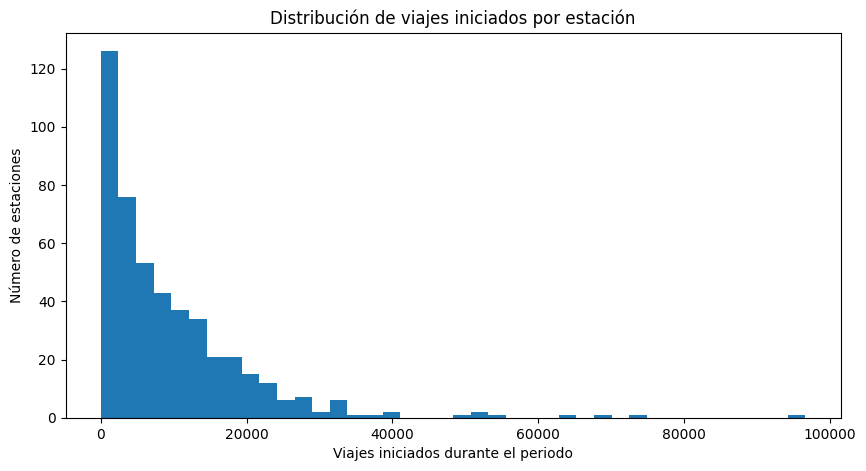

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(viajes_estacion["total_viajes"], bins=40)

plt.title("Distribución de viajes iniciados por estación")
plt.xlabel("Viajes iniciados durante el periodo")
plt.ylabel("Número de estaciones")

plt.show()

In [5]:
# Viajes que terminan en cada estación
llegadas = df.groupby("destino_id").size()

# Viajes que comienzan en cada estación
salidas = df.groupby("origen_id").size()

# Combinar resultados
estaciones = pd.DataFrame({
    "salidas": salidas,
    "llegadas": llegadas
}).fillna(0)

# Balance neto de viajes
estaciones["balance"] = estaciones["llegadas"] - estaciones["salidas"]

estaciones["balance_relativo"] = (
    (estaciones["llegadas"] - estaciones["salidas"])
    / (estaciones["llegadas"] + estaciones["salidas"])
)

estaciones.head(10)

estaciones.head(10)

,salidas,llegadas,balance,balance_relativo
2,18200,18714,514,0.013924
3,17033,14672,-2361,-0.074468
4,20478,20277,-201,-0.004932
5,18231,19086,855,0.022912
6,10639,14094,3455,0.139692
8,9643,10311,668,0.033477
9,14223,15356,1133,0.038304
10,13723,13928,205,0.007414
11,64007,58569,-5438,-0.044364
12,21892,22505,613,0.013807


In [6]:
# Extraer la hora de inicio de cada viaje
df["hora"] = df["inicio"].dt.hour

# Contar viajes por estación y hora
viajes_hora = (
    df.groupby(["origen_id", "hora"])
    .size()
    .unstack(fill_value=0)
)

# Convertir los conteos en proporciones
patrones_horarios = viajes_hora.div(
    viajes_hora.sum(axis=1),
    axis=0
)

patrones_horarios.head()

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
origen_id,,,,,,,,,,,,,,,,,,,,,
2,0.006429,0.000110,0.0,0.0,0.0,0.007363,0.042088,0.072198,0.098516,0.068352,...,0.058846,0.062198,0.068022,0.048516,0.079121,0.061813,0.065440,0.030989,0.012033,0.009451
3,0.006928,0.000000,0.0,0.0,0.0,0.004932,0.021253,0.035695,0.053484,0.076322,...,0.072624,0.065050,0.061293,0.078788,0.104503,0.075500,0.052134,0.051606,0.032173,0.017965
4,0.008009,0.000049,0.0,0.0,0.0,0.005127,0.009376,0.035599,0.060455,0.058258,...,0.058697,0.061236,0.078230,0.091562,0.109337,0.065583,0.054107,0.050689,0.030862,0.012501
5,0.002468,0.000055,0.0,0.0,0.0,0.018924,0.049092,0.095716,0.140804,0.055236,...,0.057539,0.090012,0.064560,0.045911,0.061324,0.047392,0.037464,0.022763,0.016730,0.006802
6,0.006204,0.000000,0.0,0.0,0.0,0.015227,0.018517,0.085252,0.068709,0.064856,...,0.059592,0.059686,0.067864,0.061566,0.066454,0.063822,0.044553,0.036658,0.029984,0.011091


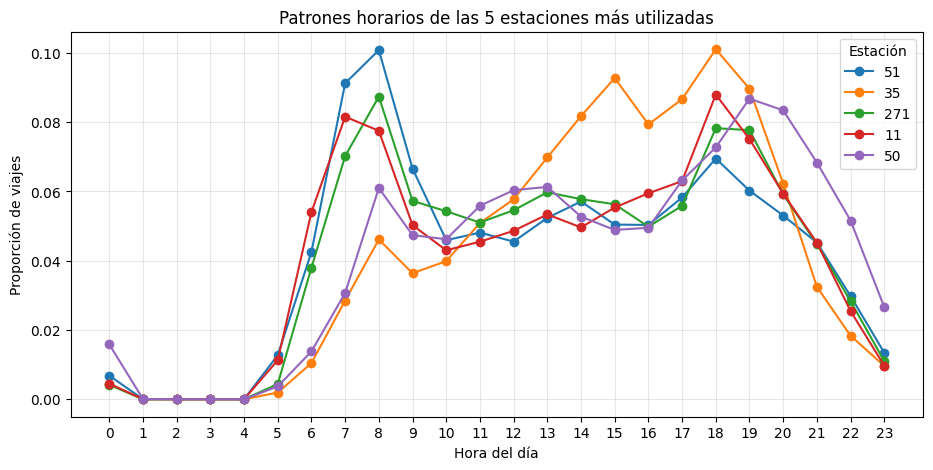

In [7]:
import matplotlib.pyplot as plt

# Seleccionar las 5 estaciones con más salidas
top_estaciones = viajes_estacion.head(5)["origen_id"]

# Graficar sus patrones horarios
patrones_horarios.loc[top_estaciones].T.plot(
    figsize=(11, 5),
    marker="o"
)

plt.title("Patrones horarios de las 5 estaciones más utilizadas")
plt.xlabel("Hora del día")
plt.ylabel("Proporción de viajes")
plt.xticks(range(24))
plt.legend(title="Estación")
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Identificar viajes en fin de semana
df["fin_semana"] = df["inicio"].dt.dayofweek >= 5

# Calcular proporción por estación
fines_semana = (
    df.groupby("origen_id")["fin_semana"]
    .mean()
    .rename("proporcion_fin_semana")
)

fines_semana.head(10)

origen_id
2     0.191868
3     0.192920
4     0.235033
5     0.190719
6     0.212802
8     0.204708
9     0.211981
10    0.194491
11    0.199119
12    0.237804
Name: proporcion_fin_semana, dtype: float64

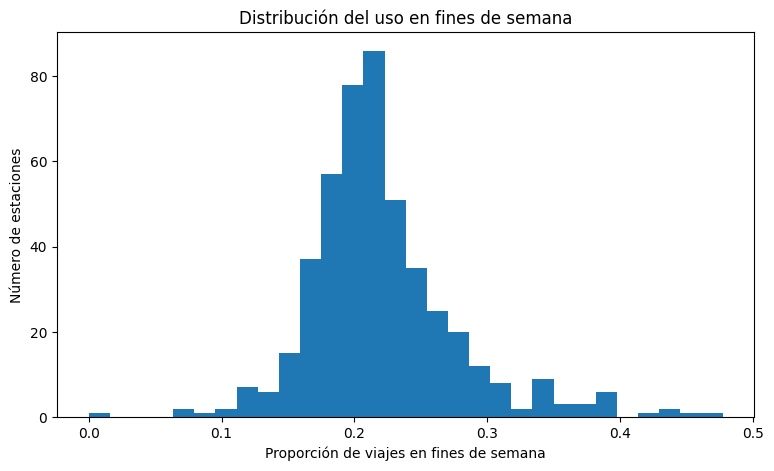

In [9]:
plt.figure(figsize=(9, 5))

plt.hist(fines_semana, bins=30)

plt.title("Distribución del uso en fines de semana")
plt.xlabel("Proporción de viajes en fines de semana")
plt.ylabel("Número de estaciones")

plt.show()

In [10]:
# Construir tabla de características
features_p3 = estaciones[
    ["salidas", "balance_relativo"]
].copy()

# Promedio diario de salidas
dias = df["inicio"].dt.normalize().nunique()

features_p3["viajes_diarios"] = (
    features_p3["salidas"] / dias
)

# Proporción de viajes en fines de semana
features_p3 = features_p3.join(fines_semana)

# Distribución horaria
features_p3 = features_p3.join(
    patrones_horarios.add_prefix("hora_")
)

features_p3.head()

,salidas,balance_relativo,viajes_diarios,proporcion_fin_semana,hora_0,hora_1,hora_2,hora_3,hora_4,hora_5,...,hora_14,hora_15,hora_16,hora_17,hora_18,hora_19,hora_20,hora_21,hora_22,hora_23
2,18200,0.013924,49.863014,0.191868,0.006429,0.000110,0.0,0.0,0.0,0.007363,...,0.058846,0.062198,0.068022,0.048516,0.079121,0.061813,0.065440,0.030989,0.012033,0.009451
3,17033,-0.074468,46.665753,0.192920,0.006928,0.000000,0.0,0.0,0.0,0.004932,...,0.072624,0.065050,0.061293,0.078788,0.104503,0.075500,0.052134,0.051606,0.032173,0.017965
4,20478,-0.004932,56.104110,0.235033,0.008009,0.000049,0.0,0.0,0.0,0.005127,...,0.058697,0.061236,0.078230,0.091562,0.109337,0.065583,0.054107,0.050689,0.030862,0.012501
5,18231,0.022912,49.947945,0.190719,0.002468,0.000055,0.0,0.0,0.0,0.018924,...,0.057539,0.090012,0.064560,0.045911,0.061324,0.047392,0.037464,0.022763,0.016730,0.006802
6,10639,0.139692,29.147945,0.212802,0.006204,0.000000,0.0,0.0,0.0,0.015227,...,0.059592,0.059686,0.067864,0.061566,0.066454,0.063822,0.044553,0.036658,0.029984,0.011091


In [11]:
# Seleccionar características principales
features_modelo = features_p3[
    ["viajes_diarios", "balance_relativo", "proporcion_fin_semana"]
].copy()

# Agrupar proporciones horarias
features_modelo["manana"] = features_p3[
    [f"hora_{h}" for h in range(6, 11)]
].sum(axis=1)

features_modelo["mediodia"] = features_p3[
    [f"hora_{h}" for h in range(11, 16)]
].sum(axis=1)

features_modelo["tarde"] = features_p3[
    [f"hora_{h}" for h in range(16, 21)]
].sum(axis=1)

features_modelo["noche"] = features_p3[
    [f"hora_{h}" for h in list(range(21, 24)) + list(range(6))]
].sum(axis=1)

features_modelo.head()

,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde,noche
2,49.863014,0.013924,0.191868,0.333132,0.277582,0.322912,0.066374
3,46.665753,-0.074468,0.192920,0.238361,0.275818,0.372219,0.113603
4,56.104110,-0.004932,0.235033,0.219943,0.274001,0.398818,0.107237
5,49.947945,0.022912,0.190719,0.390653,0.284954,0.256651,0.067742
6,29.147945,0.139692,0.212802,0.300874,0.295704,0.304258,0.099163


In [12]:
import numpy as np

print("Dimensiones:", features_modelo.shape)
print("Valores faltantes:", features_modelo.isna().sum().sum())
print("Valores infinitos:", np.isinf(features_modelo).sum().sum())
print("Estaciones con menos de 100 salidas:",
      (estaciones["salidas"] < 100).sum())

features_modelo.describe().round(3)

Dimensiones: (471, 7)
Valores faltantes: 0
Valores infinitos: 0
Estaciones con menos de 100 salidas: 1


,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde,noche
count,471.000,471.000,471.000,471.000,471.000,471.000,471.000
mean,26.159,-0.023,0.221,0.285,0.288,0.338,0.089
std,29.994,0.099,0.057,0.083,0.053,0.074,0.033
min,0.008,-0.348,0.000,0.000,0.000,0.153,0.000
25%,6.226,-0.083,0.188,0.225,0.249,0.296,0.068
50%,16.545,-0.022,0.213,0.283,0.284,0.336,0.086
75%,35.752,0.023,0.241,0.340,0.325,0.374,0.107
max,264.756,0.352,0.477,0.550,0.455,1.000,0.332


In [13]:
# Estaciones con menos de 100 viajes iniciados
estaciones[estaciones["salidas"] < 100]

,salidas,llegadas,balance,balance_relativo
405,3,3,0,0.0


In [14]:
# Excluir estaciones con menos de 100 salidas
estaciones_validas = estaciones[
    estaciones["salidas"] >= 100
].index

features_modelo = features_modelo.loc[estaciones_validas]

print("Estaciones para clustering:", len(features_modelo))

Estaciones para clustering: 470


### Conclusiones

El análisis exploratorio confirma que las estaciones de MiBici presentan diferencias tanto en su intensidad de uso como en sus patrones temporales. Esto justifica utilizar técnicas de clustering para identificar grupos de estaciones con comportamientos similares.

Se seleccionaron siete características iniciales: demanda diaria promedio, balance relativo, proporción de viajes en fines de semana y distribución de viajes en cuatro franjas horarias.

Debido a la asimetría observada en la demanda, se propone aplicar una transformación logarítmica y estandarizar las características antes del agrupamiento mediante K-Means.

Como siguiente etapa, estas transformaciones se implementarán en `features.py` para garantizar su reutilización y reproducibilidad. También se revisará la cobertura temporal de las estaciones y se evaluará la estabilidad de los grupos en diferentes periodos.

Los resultados actuales son exploratorios y no constituyen todavía evidencia de la calidad del modelo.

In [15]:
from mibici.features import crear_features_p3

features = crear_features_p3(df)

print("Dimensiones:", features.shape)
print("Valores faltantes:", features.isna().sum().sum())

features.head()

2026-10-17 10:44:24.629 | INFO     | mibici.config:<module>:11 - PROJ_ROOT path is: C:\Users\PC\Desktop\Escuela\Trimestre4\MLOps\TC5061-Proyecto-Equipo31\TC5061-Proyecto-Equipo31


Dimensiones: (470, 7)
Valores faltantes: 0


,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde,noche
2,49.863014,0.013924,0.191868,0.333132,0.277582,0.322912,0.066374
3,46.665753,-0.074468,0.192920,0.238361,0.275818,0.372219,0.113603
4,56.104110,-0.004932,0.235033,0.219943,0.274001,0.398818,0.107237
5,49.947945,0.022912,0.190719,0.390653,0.284954,0.256651,0.067742
6,29.147945,0.139692,0.212802,0.300874,0.295704,0.304258,0.099163


### Preprocesamiento de características

Se aplicó una transformación logarítmica (`log1p`) a la demanda diaria para reducir su asimetría, identificada durante el análisis exploratorio.

Posteriormente, se utilizó `StandardScaler` para estandarizar las variables y evitar que las diferencias de escala dominaran las distancias utilizadas por el algoritmo de clustering.

También se eliminó la variable `noche`, debido a que las cuatro proporciones horarias suman 1, generando redundancia.

**Resultados:**
- 470 estaciones analizadas.
- 6 características estandarizadas.
- 0 valores faltantes.

Este preprocesamiento permitirá comparar el baseline y K-Means utilizando el mismo conjunto de características.

In [17]:
from mibici.features import preprocesar_features_p3

features_escaladas, scaler = preprocesar_features_p3(features)

print("Dimensiones:", features_escaladas.shape)
print("Valores faltantes:", features_escaladas.isna().sum().sum())

features_escaladas.head()

Dimensiones: (470, 6)
Valores faltantes: 0


,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde
2,1.039230,0.372535,-0.524893,0.586507,-0.215926,-0.206612
3,0.981565,-0.524366,-0.506212,-0.572341,-0.250278,0.526172
4,1.142032,0.181204,0.242002,-0.797547,-0.285628,0.921490
5,1.040712,0.463730,-0.545308,1.289871,-0.072442,-1.191373
6,0.574676,1.648681,-0.152967,0.192064,0.136801,-0.483846


### Baseline de clustering

Se implementó un baseline sencillo que divide las estaciones en tres grupos según los terciles de su demanda diaria promedio: baja, media y alta.

Los resultados fueron:

| Grupo | Estaciones | Viajes diarios promedio |
|---|---:|---:|
| 0 — Baja demanda | 157 | 3.98 |
| 1 — Media demanda | 156 | 17.84 |
| 2 — Alta demanda | 157 | 56.77 |

Para evaluar la calidad de las agrupaciones se utilizó **Silhouette Score**, calculado sobre las seis características estandarizadas.

**Resultado: Silhouette Score = 0.0732**

Este valor indica una separación débil entre los grupos en el espacio de características utilizado. Aunque el baseline distingue niveles de demanda, no necesariamente representa adecuadamente las diferencias en patrones horarios, uso en fines de semana y balance de viajes.

Por ello, el baseline servirá como referencia para evaluar posteriormente K-Means, que considerará simultáneamente las distintas características de cada estación.

In [18]:
from mibici.features import baseline_p3

grupos = baseline_p3(features)

print("Estaciones por grupo:")
print(grupos.value_counts().sort_index())

print("\nDemanda promedio por grupo:")
print(features.groupby(grupos)["viajes_diarios"].mean())

Estaciones por grupo:
cluster
0    157
1    156
2    157
Name: count, dtype: int64

Demanda promedio por grupo:
cluster
0     3.984172
1    17.840130
2    56.766181
Name: viajes_diarios, dtype: float64


In [19]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    features_escaladas,
    grupos
)

print(f"Silhouette Score del baseline: {score:.4f}")

Silhouette Score del baseline: 0.0732


In [22]:
from mibici.features import entrenar_kmeans_p3
from sklearn.metrics import silhouette_score

# Entrenar K-Means
grupos_kmeans, modelo_kmeans = entrenar_kmeans_p3(
    features_escaladas,
    n_clusters=3,
)

# Evaluar agrupaciones
score_kmeans = silhouette_score(
    features_escaladas,
    grupos_kmeans,
)

print("Silhouette Baseline:", round(score, 4))
print("Silhouette K-Means:", round(score_kmeans, 4))

print("\nEstaciones por cluster:")
print(grupos_kmeans.value_counts().sort_index())

Silhouette Baseline: 0.0732
Silhouette K-Means: 0.1992

Estaciones por cluster:
cluster
0    154
1    198
2    118
Name: count, dtype: int64


In [23]:
# Promedios de características originales por cluster
perfiles = features.groupby(grupos_kmeans).mean()

print("Características promedio por cluster:")
display(perfiles.round(3))

Características promedio por cluster:


,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde,noche
cluster,,,,,,,
0,8.325,-0.005,0.251,0.364,0.275,0.277,0.084
1,47.631,0.017,0.208,0.258,0.306,0.343,0.093
2,13.626,-0.113,0.204,0.228,0.278,0.405,0.090


In [24]:
# Calcular características promedio por cluster
perfiles = features.groupby(grupos_kmeans).mean()

display(perfiles.round(3))

,viajes_diarios,balance_relativo,proporcion_fin_semana,manana,mediodia,tarde,noche
cluster,,,,,,,
0,8.325,-0.005,0.251,0.364,0.275,0.277,0.084
1,47.631,0.017,0.208,0.258,0.306,0.343,0.093
2,13.626,-0.113,0.204,0.228,0.278,0.405,0.090


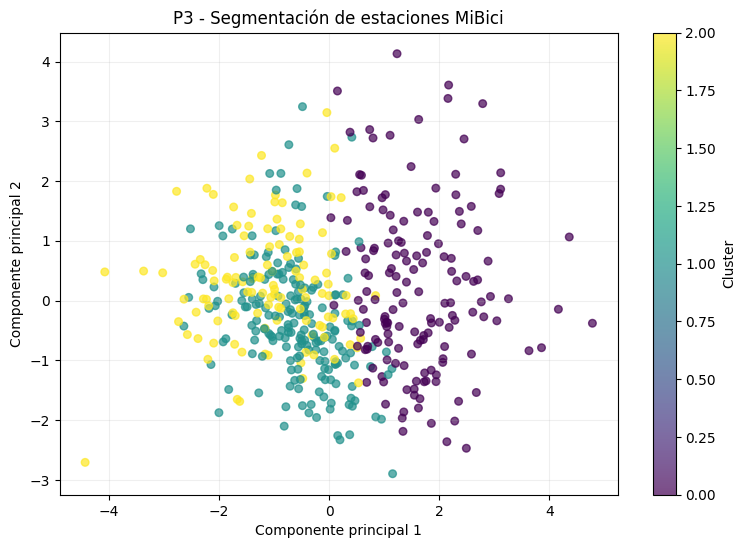

Varianza explicada: 56.34 %


In [25]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reducir las 6 características a 2 componentes
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(features_escaladas)

# Visualizar los clusters
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    coordenadas[:, 0],
    coordenadas[:, 1],
    c=grupos_kmeans,
    cmap="viridis",
    alpha=0.7,
    s=30
)

plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.title("P3 - Segmentación de estaciones MiBici")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.2)
plt.show()

print(
    "Varianza explicada:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [26]:
import pandas as pd

pesos = pd.DataFrame(
    pca.components_.T,
    index=features_escaladas.columns,
    columns=["Componente 1", "Componente 2"]
)

display(pesos.round(3))

,Componente 1,Componente 2
viajes_diarios,-0.338,-0.340
balance_relativo,0.140,-0.393
proporcion_fin_semana,0.239,0.621
manana,0.641,-0.248
mediodia,-0.185,0.527
tarde,-0.603,-0.079


### Interpretación de los clusters de K-Means

Se aplicó K-Means con **tres clusters** sobre seis características estandarizadas de **470 estaciones**, obteniendo un Silhouette Score de **0.1992**, superior al baseline de **0.0732**. Esto representa una mejora en la separación de los grupos, aunque todavía existe cierta superposición entre ellos.

El análisis de las características promedio permitió identificar tres perfiles:

- **Cluster 0 (154 estaciones):** Estaciones de baja demanda (8.33 viajes diarios), con mayor proporción de salidas matutinas (36.4%) y uso relativamente elevado durante fines de semana (25.1%). Presentan un balance de viajes prácticamente neutro.
- **Cluster 1 (198 estaciones):** Estaciones de alta demanda (47.63 viajes diarios), con actividad concentrada principalmente durante el mediodía (30.6%) y la tarde (34.3%). Su balance de viajes es ligeramente positivo.
- **Cluster 2 (118 estaciones):** Estaciones de demanda intermedia-baja (13.63 viajes diarios), con predominio de salidas vespertinas (40.5%) y un balance relativo negativo (−0.113), indicando más salidas que llegadas.

Para visualizar los resultados, se utilizó **Análisis de Componentes Principales (PCA)**, reduciendo las seis características a dos dimensiones. La gráfica permitió observar una diferenciación parcial de los clusters, aunque también mostró superposición entre algunos grupos, especialmente los clusters 1 y 2.

Los resultados sugieren que K-Means identifica diferencias de demanda, comportamiento horario y balance de viajes, ofreciendo una segmentación más completa que el baseline basado únicamente en demanda.

Desde una perspectiva operativa, estos grupos podrían apoyar la identificación de estaciones con alta actividad, patrones horarios particulares o posibles necesidades de rebalanceo. Sin embargo, antes de recomendar acciones concretas, sería necesario evaluar la estabilidad temporal de los clusters y considerar la ubicación geográfica de las estaciones.